In [66]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [67]:

headers = {
    "accept": "application/json",
    "x-cg-demo-api-key": str(os.getenv('COIN_API'))
}

In [68]:
response_1 = requests.get(
    "https://api.coingecko.com/api/v3/coins/bitcoin/market_chart?vs_currency=usd&days=90",
    headers=headers
)

data = response_1.json()

# Convert prices to DataFrame
df_prices = pd.DataFrame(data['prices'], columns=['timestamp', 'price'])
df_prices['timestamp'] = pd.to_datetime(df_prices['timestamp'], unit='ms')

# Convert market caps to DataFrame
#df_mcap = pd.DataFrame(data['market_caps'], columns=['timestamp', 'market_cap'])
#df_mcap['timestamp'] = pd.to_datetime(df_mcap['timestamp'], unit='ms')

# Convert volumes to DataFrame
df_volume = pd.DataFrame(data['total_volumes'], columns=['timestamp', 'volume'])
df_volume['timestamp'] = pd.to_datetime(df_volume['timestamp'], unit='ms')

# Merge all into one DataFrame
df_combined = df_prices.merge(df_volume, on='timestamp')

# --- Returns (this is your new prediction target) ---
df_combined['log_return'] = np.log(df_combined['price'] / df_combined['price'].shift(1))

# --- A few extra features that pair well with returns ---
df_combined['log_return_lag1'] = df_combined['log_return'].shift(1)
df_combined['log_return_lag2'] = df_combined['log_return'].shift(2)
df_combined['volatility_6'] = df_combined['log_return'].rolling(6).std()   # rolling realized vol
df_combined['volume_change'] = df_combined['volume'].pct_change()

df_combined = df_combined.dropna().reset_index(drop=True)

df_combined

,timestamp,price,volume,log_return,log_return_lag1,log_return_lag2,volatility_6,volume_change
0,2026-05-07 05:00:00,80991.188249,3.961450e+10,0.001969,-0.003374,-0.000690,0.002943,0.017290
1,2026-05-07 06:00:00,81055.578401,3.367507e+10,0.000795,0.001969,-0.003374,0.002907,-0.149931
2,2026-05-07 07:00:00,81430.363404,3.930594e+10,0.004613,0.000795,0.001969,0.002700,0.167212
3,2026-05-07 08:00:00,81527.347332,3.484641e+10,0.001190,0.004613,0.000795,0.002672,-0.113457
4,2026-05-07 09:00:00,81198.233530,3.857409e+10,-0.004045,0.001190,0.004613,0.003309,0.106975
...,...,...,...,...,...,...,...,...
2150,2026-08-04 19:00:00,64253.347630,2.330640e+10,0.004172,-0.000058,-0.000857,0.003951,0.016835
2151,2026-08-04 20:00:00,64231.814226,2.320549e+10,-0.000335,0.004172,-0.000058,0.003507,-0.004330
2152,2026-08-04 21:00:00,64296.777039,2.344880e+10,0.001011,-0.000335,0.004172,0.001951,0.010485
2153,2026-08-04 22:00:00,64149.209429,2.307559e+10,-0.002298,0.001011,-0.000335,0.002196,-0.015916


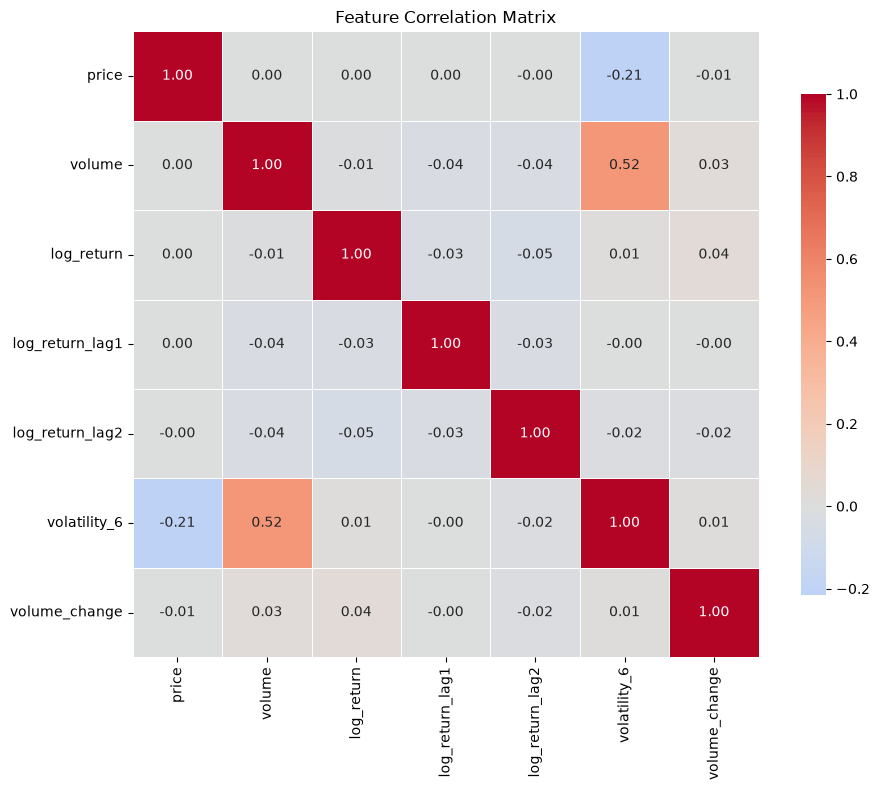

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix (only numeric columns, drop timestamp)
corr = df_combined.drop(columns=['timestamp']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Build the feature matrix from the transformed target and associated market features
# Keep the model predicting the next step's log_return, not the absolute price.

#values = df_combined[["log_return", "market_cap", "volume"]].to_numpy(dtype=np.float32)
values = df_combined[["price", "volume", 'log_return',
                       'log_return_lag2', 'log_return_lag1', 'volatility_6', 'volume_change']].to_numpy(dtype=np.float32)
 
train_end = int(len(values) * 0.7)
val_end = int(len(values) * 0.85)

train = values[:train_end]
val = values[train_end:val_end]
test = values[val_end:]

# Fit scaler on TRAIN only
mean = train.mean(axis=0)
std = train.std(axis=0)
std[std == 0] = 1.0

train = (train - mean) / std
val = (val - mean) / std
test = (test - mean) / std

def windows(data, seq_len=12):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len, 2])  
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

X_train, y_train = windows(train)
X_val, y_val = windows(val)
X_test, y_test = windows(test)

print(X_train.shape)
print(X_val.shape)

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


(1496, 12, 7)
(311, 12, 7)


In [71]:
class Model(nn.Module):
    def __init__(self, input_size,hidden_size,num_stacked_layers,batch_first=True):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_stacked_layers = num_stacked_layers
        self.lstm = nn.LSTM(self.input_size,hidden_size,self.num_stacked_layers,batch_first=batch_first)
        self.linear = nn.Linear(hidden_size,1)


    def forward(self,x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        c0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        out, _ = self.lstm(x,(h0,c0))
        out = self.linear(out[:,-1,:])
        return out

model = Model(X_train.shape[-1], hidden_size=5, num_stacked_layers=2)
model

Model(
  (lstm): LSTM(7, 5, num_layers=2, batch_first=True)
  (linear): Linear(in_features=5, out_features=1, bias=True)
)

In [72]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

Epoch 1/100 - train_loss: 0.337898 - val_loss: 0.202883
Epoch 2/100 - train_loss: 0.335600 - val_loss: 0.196791
Epoch 3/100 - train_loss: 0.335366 - val_loss: 0.196984
Epoch 4/100 - train_loss: 0.335053 - val_loss: 0.200005
Epoch 5/100 - train_loss: 0.333546 - val_loss: 0.196668
Epoch 6/100 - train_loss: 0.331538 - val_loss: 0.199152
Epoch 7/100 - train_loss: 0.335022 - val_loss: 0.197761
Epoch 8/100 - train_loss: 0.332574 - val_loss: 0.196950
Epoch 9/100 - train_loss: 0.328871 - val_loss: 0.196983
Epoch 10/100 - train_loss: 0.328413 - val_loss: 0.199068
Epoch 11/100 - train_loss: 0.325708 - val_loss: 0.200149
Epoch 12/100 - train_loss: 0.324614 - val_loss: 0.198883
Epoch 13/100 - train_loss: 0.323556 - val_loss: 0.199845
Epoch 14/100 - train_loss: 0.325039 - val_loss: 0.199389
Epoch 15/100 - train_loss: 0.320621 - val_loss: 0.203664
Epoch 16/100 - train_loss: 0.320484 - val_loss: 0.200006
Epoch 17/100 - train_loss: 0.317058 - val_loss: 0.200815
Epoch 18/100 - train_loss: 0.315313 - va

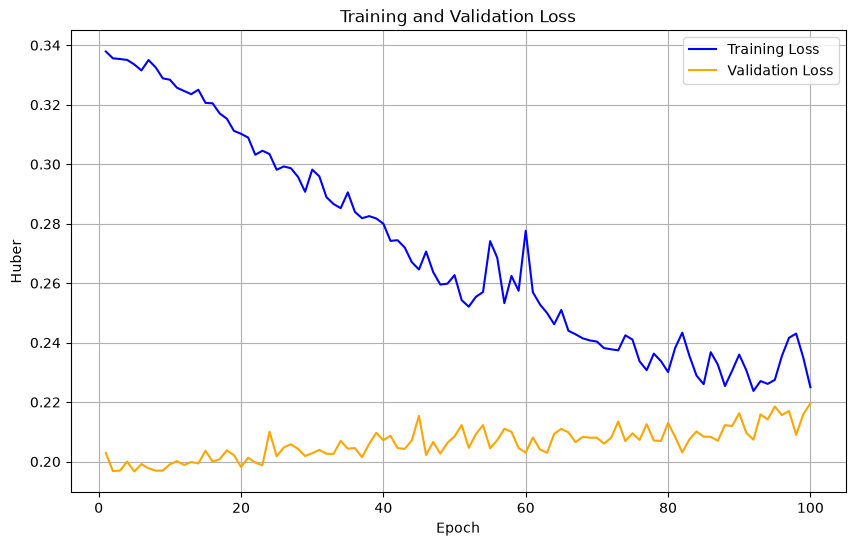

In [73]:
import matplotlib.pyplot as plt

learning_rate = 0.01
num_epochs = 100
criterion = nn.HuberLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Huber")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [74]:
model.eval()

test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.190829


In [ ]:

 
model.eval()
preds, actuals = [], []
with torch.no_grad():
    for feature, label in test_data_loader:
        preds.append(model(feature).squeeze(-1))
        actuals.append(label)
preds = torch.cat(preds)
actuals = torch.cat(actuals)
 
# --- 2. Mean baseline: predict the mean of TRAINING log returns ---
#    y_train is already z-scored, so this is ~0 (predicting "no change").
#    Using the train mean (not the test mean) avoids leakage.
baseline_value = y_train.mean()
baseline_preds = torch.full_like(actuals, float(baseline_value))
 
# --- 3. Evaluate both with identical metrics ---
def report(pred, target, name):
    mse  = ((pred - target) ** 2).mean()
    mae  = (pred - target).abs().mean()
    huber = nn.HuberLoss()(pred, target)
    print(f"{name:>14} | Huber: {huber:.6f} | RMSE: {mse.sqrt():.6f} | MAE: {mae:.6f}")
 
print("NORMALIZED space (what your test loss is reported in):")
report(preds, actuals, "LSTM")
report(baseline_preds, actuals, "Mean baseline")
 
# --- 4. Undo the z-score so numbers are real log returns ---
logret_mean, logret_std = mean[2], std[2]
 
pred_lr   = preds   * logret_std + logret_mean
base_lr   = baseline_preds * logret_std + logret_mean
actual_lr = actuals * logret_std + logret_mean
 
print("\nREAL log-return space (0.01 ≈ a 1% move):")
report(pred_lr, actual_lr, "LSTM")
report(base_lr, actual_lr, "Mean baseline")
 
print(f"\nBaseline predicts: {float(baseline_value):.4f} (normalized)")
print(f"                 = {float(base_lr[0]):.6f} log return ≈ {np.exp(float(base_lr[0])) - 1:.2%} per step")

NORMALIZED space (what your test loss is reported in):
          LSTM | Huber: 0.191434 | RMSE: 0.678415 | MAE: 0.464414
 Mean baseline | Huber: 0.185730 | RMSE: 0.666344 | MAE: 0.448760

REAL log-return space (0.01 ≈ a 1% move):
          LSTM | Huber: 0.000005 | RMSE: 0.003179 | MAE: 0.002176
 Mean baseline | Huber: 0.000005 | RMSE: 0.003122 | MAE: 0.002103

Baseline predicts: 0.0014 (normalized)
                 = -0.000167 log return ≈ -0.02% per step


In [76]:
'''
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "learning_rate": learning_rate,
    "num_epochs": num_epochs,
    "mean": mean,
    "std": std,
    "price_mean": price_mean,
    "price_std": price_std,
    "training_loss": training_loss,
    "testing_loss": testing_loss,
    "rmse_usd": rmse,
    "mae_usd": mae
}, "bitcoin_lstm_model.pt")

'''

'\ntorch.save({\n    "model_state_dict": model.state_dict(),\n    "optimizer_state_dict": optimizer.state_dict(),\n    "learning_rate": learning_rate,\n    "num_epochs": num_epochs,\n    "mean": mean,\n    "std": std,\n    "price_mean": price_mean,\n    "price_std": price_std,\n    "training_loss": training_loss,\n    "testing_loss": testing_loss,\n    "rmse_usd": rmse,\n    "mae_usd": mae\n}, "bitcoin_lstm_model.pt")\n\n'